In [ ]:
import pandas as pd
import numpy as np

from google.colab import drive


drive.mount('/content/drive')
path ="/content/drive/MyDrive/ecommerce_customer_churn_dataset.csv"
df = pd.read_csv(path)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [ ]:

# 1.  (عدد الصفوف والأعمدة)
print("Dataset Shape:")
display(df.shape)

# 2. عرض أول 5 صفوف لمعاينة البيانات بشكل مرئي
print("\nFirst 5 Rows:")
display(df.head())

# 3. عرض معلومات تفصيلية عن أنواع البيانات في الأعمدة
print("\nDataset Info:")
df.info()

# 4. فحص وحساب عدد القيم المفقودة (الفارغة) في كل عمود
print("\nMissing Values:")
display(df.isnull().sum())




Dataset Shape:


(50000, 25)


First 5 Rows:


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       

,0
Age,2495
Gender,0
Country,0
City,0
Membership_Years,0
Login_Frequency,0
Session_Duration_Avg,3399
Pages_Per_Session,3000
Cart_Abandonment_Rate,0
Wishlist_Items,4000


In [ ]:
#خطوة تنظيف عمود العمرت


# 1. حساب  (الوسيط) لأعمار العملاء وتخزينها في متغير
age_median = df['Age'].median()

# 2. طباعة قيمة الوسيطا
print("القيمة الوسطى للعمر هي:")
display(age_median)

# 3. وضع هذا الرقم في الأماكن الفارغة داخل عمود العمر
df['Age'] = df['Age'].fillna(age_median)

# 4. التأكد من أن عمود العمر أصبح نظيفاً تماماً ولا يحتوي على فراغات
print("\nعدد القيم الفارغة في عمود العمر بعد التنظيف:")
display(df['Age'].isnull().sum())

القيمة الوسطى للعمر هي:


38.0


عدد القيم الفارغة في عمود العمر بعد التنظيف:


np.int64(0)

In [ ]:

# خطوة تنظيف عمود متوسط مدة الجلست

# 1.
session_median = df['Session_Duration_Avg'].median()

# 2.
print("القيمة الوسطى لمدد الجلسات هي:")
display(session_median)

# 3.
df['Session_Duration_Avg'] = df['Session_Duration_Avg'].fillna(session_median)

# 4.
print("\nعدد القيم الفارغة في عمود مدد الجلسات بعد التنظيف:")
display(df['Session_Duration_Avg'].isnull().sum())

القيمة الوسطى لمدد الجلسات هي:


26.8


عدد القيم الفارغة في عمود مدد الجلسات بعد التنظيف:


np.int64(0)

In [ ]:
# خطوة تنظيف كافة الأعمدة الرقمية المتبقية في الجدول

# 1. أمر يمر على كل الاعمدة الرقمية وبحسب الها الوسيط وبحطه مكان القيم الفارغة بدل م اضل اعمل عمود عمود
df = df.fillna(df.median(numeric_only=True))

# 2. التاكد ان الجدول لا يحتوي على قيم فارغة
print("الفحص النهائي لجميع الأعمدة بعد التنظيف:")
display(df.isnull().sum())

الفحص النهائي لجميع الأعمدة بعد التنظيف:


,0
Age,0
Gender,0
Country,0
City,0
Membership_Years,0
Login_Frequency,0
Session_Duration_Avg,0
Pages_Per_Session,0
Cart_Abandonment_Rate,0
Wishlist_Items,0


In [ ]:
# 1. البحث عن الصفوف المكررة بالكامل وحساب مجموعها
duplicate_count = df.duplicated().sum()

# 2. طباعة النتيجة لنعرف كم صفاً مكرراً لدينا
print("عدد الصفوف المكررة في الجدول هو:")
display(duplicate_count)

عدد الصفوف المكررة في الجدول هو:


np.int64(0)

In [ ]:
#فحصت حجم الداتا وشو نوعها
#عبيت القيم الفارغة باستخدام الوسيط لكل عمود رقمي
#اتاكدت م في تكرار في الصفوف

In [ ]:
#حبدا شغل في categorie
df = df = pd.read_csv(path)
print("الكلمات الموجودة في عمود الجنس وعدد تكرار كل كلمة:")
display(df['Gender'].value_counts())

الكلمات الموجودة في عمود الجنس وعدد تكرار كل كلمة:


,count
Gender,
Female,25116
Male,23947
Other,937


In [ ]:
#ححول الكلمات لارقام في عمود الجنس
# 1. استبدال الكلمات الثلاث بأرقام (0، 1، 2) وحفظ التعديل في نفس العمود
df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1, 'Other': 2})

# 2. معاينة أول 5 صفوف للعمود للتأكد من نجاح العملية
print("شكل عمود الجنس بعد الاستبدال المباشر:")
display(df['Gender'].head())

شكل عمود الجنس بعد الاستبدال المباشر:


/tmp/ipykernel_2001/520958081.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1, 'Other': 2})


,Gender
0,1
1,1
2,0
3,0
4,1


In [ ]:

# عمود الدولة

print("الدول الموجودة في عمود Country وعدد تكرار كل دولة:")
display(df['Country'].value_counts())

الدول الموجودة في عمود Country وعدد تكرار كل دولة:


,count
Country,
USA,17384
UK,7534
Canada,6023
Germany,4925
Australia,4061
France,4013
India,3512
Japan,2548


In [ ]:
# 1. استبدال أسماء الدول الثمانية بأرقام (من 0 إلى 7) وحفظ التعديل مكانها
df['Country'] = df['Country'].replace({
    'USA': 0,
    'UK': 1,
    'Canada': 2,
    'Germany': 3,
    'Australia': 4,
    'France': 5,
    'India': 6,
    'Japan': 7
})

# 2. معاينة أول 5 صفوف لعمود الدول للتأكد من نجاح العملية
print("شكل عمود الدول بعد الاستبدال المباشر:")
display(df['Country'].head())

شكل عمود الدول بعد الاستبدال المباشر:


/tmp/ipykernel_2001/4248542227.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Country'] = df['Country'].replace({


,Country
0,5
1,1
2,2
3,0
4,6


In [ ]:
#عمود المدن
print("المدن الموجودة في عمود City وعدد تكرار كل مدينة:")
display(df['City'].value_counts())

المدن الموجودة في عمود City وعدد تكرار كل مدينة:


,count
City,
Houston,3549
Phoenix,3490
New York,3477
Chicago,3475
Los Angeles,3393
Manchester,1576
Birmingham,1535
Leeds,1529
London,1458


In [ ]:
#عشان عدد المدن كتيرة بدل م اكتبهم وحدة وحدة كتبنا كود يعملهم بشكل تلقائي
# 1.  ربط كل مدينة فريدة برقم تلقائي (0، 1، 2...)
city_map = {city: index for index, city in enumerate(df['City'].unique())}

# 2. استبدال أسماء المدن بالأرقام التي تم توليدها وحفظ التعديل
df['City'] = df['City'].replace(city_map)

# 3. عرض أول 5 صفوف لعمود المدن للتأكد من تحولها بنجاح
print("شكل عمود المدن بعد التشفير الذكي:")
display(df['City'].head())

شكل عمود المدن بعد التشفير الذكي:


/tmp/ipykernel_2001/2451483300.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['City'] = df['City'].replace(city_map)


,City
0,0
1,1
2,2
3,3
4,4


In [ ]:
#عمود الربح السنوي
print("القيم الموجودة في عمود الربع السنوي وتكرارها:")
display(df['Signup_Quarter'].value_counts())

القيم الموجودة في عمود الربع السنوي وتكرارها:


,count
Signup_Quarter,
Q3,12558
Q2,12521
Q4,12468
Q1,12453


In [ ]:
# خطوة تحويل الربع السنوي إلى أرقام في عمود Signup_Quarter

df['Signup_Quarter'] = df['Signup_Quarter'].replace({
    'Q1': 1,
    'Q2': 2,
    'Q3': 3,
    'Q4': 4
})
print("شكل عمود الربع السنوي بعد التشفير المباشر:")
display(df['Signup_Quarter'].head())

شكل عمود الربع السنوي بعد التشفير المباشر:


/tmp/ipykernel_2001/3275178978.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Signup_Quarter'] = df['Signup_Quarter'].replace({


,Signup_Quarter
0,1
1,4
2,4
3,1
4,4


In [ ]:
#التاكد انو كل الي عملتو تنفذ

# 1. طباعة معلومات الجدول للتأكد من أنواع البيانات (Dtype) وعدم وجود فراغات
print("معلومات الجدول النهائية:")
df.info()

print("\n" + "="*50 + "\n")

# 2. عرض أول 5 صفوف لشكل الجدول النهائي كاملاً
print("شكل الجدول النهائي بكافة أعمدته الرقمية:")
display(df.head())

معلومات الجدول النهائية:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  int64  
 2   Country                        50000 non-null  int64  
 3   City                           50000 non-null  int64  
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purch

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,1,5,0,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,1
1,36.0,1,1,1,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,4
2,45.0,0,2,2,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,4
3,56.0,0,0,3,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,1
4,35.0,1,6,4,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,4


In [ ]:
#فحصت حجم الداتا وشو نوعها
#عبيت القيم الفارغة باستخدام الوسيط لكل عمود رقمي
#اتاكدت م في تكرار في الصفوف
#كل الجدول صار عبارة عن ارقام

In [ ]:
#خطوة المرحلة القادمة: معالجة القيم المفقودة (Handling Missing Values)
# خطوة: معرفة عدد القيم المفقودة (الفارغة) في كل عمود
#صار عندي خلل لما قراءت الملف تاني وانا بحول الكلمات فبدي ارجع اعبي الفراغات بسرعو
print("عدد الخلايا الفارغة في كل عمود من أعمدة الجدول:")
display(df.isnull().sum())

عدد الخلايا الفارغة في كل عمود من أعمدة الجدول:


,0
Age,2495
Gender,0
Country,0
City,0
Membership_Years,0
Login_Frequency,0
Session_Duration_Avg,3399
Pages_Per_Session,3000
Cart_Abandonment_Rate,0
Wishlist_Items,4000


In [ ]:

# كود سريع ومختصر لملء كل الفراغات بالوسيط دفعة واحدة

# 1. تحديد الأعمدة الرقمية تلقائياً
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# 2. حلقة تكرار تمر على الأعمدة وتملأ الفراغات بالوسيط
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# 3. طباعة للتأكد من أن كل الفراغات اختفت
print("إجمالي الخلايا الفارغة المتبقية في الجدول بعد الحركة الذكية:")
print(df.isnull().sum().sum())

إجمالي الخلايا الفارغة المتبقية في الجدول بعد الحركة الذكية:
0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#بدي ادخل على مرحلة(Feature Engineering

# الخطوة 1: حساب متوسط سعر القطعة الواحدة التي يشتريها العميل

# قسمنا معدل قيمة الطلب على إجمالي المشتريات (وأضفنا 1 تجنباً للقسمة على صفر)
df['Average_Item_Value'] = df['Average_Order_Value'] / (df['Total_Purchases'] + 1)

# معاينة العمود الجديد مع الأعمدة الأصلية التي صنعناه منها لنرى النتيجة بالعين
print("العمود الجديد مقارنة بالأعمدة الأصلية:")
display(df[['Average_Order_Value', 'Total_Purchases', 'Average_Item_Value']].head())

العمود الجديد مقارنة بالأعمدة الأصلية:


,Average_Order_Value,Total_Purchases,Average_Item_Value
0,94.72,9.0,9.472000
1,82.45,19.5,4.021951
2,165.52,9.1,16.388119
3,147.33,15.0,9.208125
4,141.30,32.5,4.217910


In [ ]:

# الخطوة 2: حساب كثافة التصفح (عدد الصفحات المفتوحة في الدقيقة)


# قسمنا عدد الصفحات على معدل وقت الزيارة (وأضفنا 1 تجنباً للقسمة على صفر)
df['Pages_Per_Minute'] = df['Pages_Per_Session'] / (df['Session_Duration_Avg'] + 1)

# معاينة العمود الجديد مع الأعمدة الأصلية لنرى النتيجة بالعين
print("ميزة كثافة التصفح الجديدة مقارنة بالأعمدة الأصلية:")
display(df[['Pages_Per_Session', 'Session_Duration_Avg', 'Pages_Per_Minute']].head())

ميزة كثافة التصفح الجديدة مقارنة بالأعمدة الأصلية:


,Pages_Per_Session,Session_Duration_Avg,Pages_Per_Minute
0,6.0,27.4,0.211268
1,10.3,42.7,0.235698
2,1.6,24.8,0.062016
3,14.8,38.4,0.375635
4,8.4,51.4,0.160305


In [ ]:

# الخطوة 3: حساب مؤشر الشراء الفعلي مقارنة بترك السلة

# قسمنا المشتريات على معدل ترك السلة
# (أضفنا 0.01 في الأسفل لأن معدل ترك السلة قد يكون صفر تماماً عند بعض العملاء، وتجنباً للقسمة على صفر)
df['Purchase_To_Abandon_Ratio'] = df['Total_Purchases'] / (df['Cart_Abandonment_Rate'] + 0.01)

# معاينة العمود الجديد مع الأعمدة الأصلية لنرى الكتالوج النهائي
print("ميزة مؤشر الشراء الفعلي مقارنة بترك السلة:")
display(df[['Total_Purchases', 'Cart_Abandonment_Rate', 'Purchase_To_Abandon_Ratio']].head())

ميزة مؤشر الشراء الفعلي مقارنة بترك السلة:


,Total_Purchases,Cart_Abandonment_Rate,Purchase_To_Abandon_Ratio
0,9.0,50.6,0.177830
1,19.5,37.7,0.517104
2,9.1,70.9,0.128332
3,15.0,41.7,0.359626
4,32.5,19.1,1.700680


In [ ]:

#  مقارنة إنفاق العميل بمتوسط الإنفاق في دولته باستخدام groupby


# 1. حساب متوسط الإنفاق لكل دولة وتوزيعه على الصفوف باستخدام transform
country_mean_spend = df.groupby('Country')['Average_Order_Value'].transform('mean')

# 2. إنشاء الميزة الجديدة: قسمة إنفاق العميل الفعلي على متوسط دولته
df['Country_Spend_Ratio'] = df['Average_Order_Value'] / country_mean_spend

# 3. معاينة النتيجة بالعين للتأكد من دقة الحسابات الإحصائية
print("الميزة الاحترافية الجديدة باستخدام groupby:")
display(df[['Country', 'Average_Order_Value', 'Country_Spend_Ratio']].head())

الميزة الاحترافية الجديدة باستخدام groupby:


,Country,Average_Order_Value,Country_Spend_Ratio
0,5,94.72,0.754234
1,1,82.45,0.654689
2,2,165.52,1.343248
3,0,147.33,1.199137
4,6,141.30,1.162719


In [ ]:

#: التأكد من سلامة منطق البزنس في البيانات


print("1. فحص القيم الصغرى والكبرى للأعمدة الأساسية (للتأكد من عدم وجود قيم سالبة خاطئة):")
display(df[['Age', 'Total_Purchases', 'Average_Order_Value', 'Country_Spend_Ratio']].describe().loc[['min', 'max']])

print("\n2. فحص التوازن في عمود الهدف (Churned) لمعرفة نسبة المغادرين للبزنس:")
print(df['Churned'].value_counts(normalize=True) * 100)

1. فحص القيم الصغرى والكبرى للأعمدة الأساسية (للتأكد من عدم وجود قيم سالبة خاطئة):


,Age,Total_Purchases,Average_Order_Value,Country_Spend_Ratio
min,5.0,-13.0,26.380000,0.214710
max,200.0,128.7,9666.379178,76.755231



2. فحص التوازن في عمود الهدف (Churned) لمعرفة نسبة المغادرين للبزنس:
Churned
0    71.1
1    28.9
Name: proportion, dtype: float64


In [ ]:

# طريقة بديلة: تعديل القيم الشاذة (Capping) بدل حذف الصفوف


# 1. استخدام دالة clip لتعديل أي قيمة خارج الحدود تلقائياً
# بالنسبة للعمر: أي شيء فوق 80 يصبح 80
df['Age'] = df['Age'].clip(upper=80)

# بالنسبة للمشتريات: أي شيء تحت الصفر يصبح صفر
df['Total_Purchases'] = df['Total_Purchases'].clip(lower=0)

# 2. إعادة الفحص بالعين للتأكد من نجاح العملية
print("الفحص التجاري بعد طريقة التعديل الذكية (Capping):")
display(df[['Age', 'Total_Purchases', 'Average_Order_Value']].describe().loc[['min', 'max']])

print(f"\nحجم البيانات الإجمالي (لاحظي لم نخسر أي صف): {df.shape[0]} صف")

الفحص التجاري بعد طريقة التعديل الذكية (Capping):


,Age,Total_Purchases,Average_Order_Value
min,5.0,0.0,26.380000
max,80.0,128.7,9666.379178



حجم البيانات الإجمالي (لاحظي لم نخسر أي صف): 50000 صف


In [ ]:
#كدا الداتا جهزت زبطتها وعملت منها علاقات ببعض زي ما شرحت فوق
#حبلش هلا بتقسيم الداتا

In [ ]:
# ============================================================
# Step 5: Select Features and Target (تطبيق داتا البزنس)
# ============================================================

# Features: نأخذ الجدول كاملاً بجميع أعمدته الـ 28 المتطورة ونحذف فقط عمود الهدف
X = df.drop(columns=['Churned'])

# Target: عمود الهدف الذي نريد توقعه وهو المغادرة
y = df['Churned']

print("Features shape (أبعاد الميزات المتطورة):", X.shape)
print("Target shape (أبعاد عمود الهدف):", y.shape)

print("\n" + "="*50 + "\n")

# ============================================================
# Step 6: Split Data into Training and Testing Sets (80% to 20%)
# ============================================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42 # لتثبيت عشوائية التقسيم كما شرحتِ بالظبط!
)

print("Training Features (ميزات التدريب):", X_train.shape)
print("Testing Features (ميزات الاختبار):", X_test.shape)
print("Training Target (هدف التدريب):", y_train.shape)
print("Testing Target (هدف الاختبار):", y_test.shape)

Features shape (أبعاد الميزات المتطورة): (50000, 28)
Target shape (أبعاد عمود الهدف): (50000,)


Training Features (ميزات التدريب): (40000, 28)
Testing Features (ميزات الاختبار): (10000, 28)
Training Target (هدف التدريب): (40000,)
Testing Target (هدف الاختبار): (10000,)


In [ ]:
#حبدا في عملية بناء الخوارزميات (Model Building)
#شوفت مين افضل 4 خوارزميات بتناسب مشروعي
#Logistic Regression (الأبسط) ──> SVM ──> Random Forest ──> XGBoost
#حبدا في المودل الاضعف والابسط

In [ ]:
#  وثبتت المودل استدعيت الليبري
#from sklearn.linear_model import LogisticRegression
#log_model = LogisticRegression(random_state=42)
#بدرب المودل
#log_model.fit(X_train_scaled, y_train)
#y_pred_log = log_model.predict(X_test_scaled)
#from sklearn.metrics import accuracy_score

#log_accuracy = accuracy_score(y_test, y_pred_log)
#print(log_accuracy)


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# خطوة 1: تنظيف ميزات التدريب والاختبار من أي قيم ما لا نهاية (inf)


# تحويل أي قيمة ما لا نهاية (inf) إلى قيم فارغة (NaN) داخل X_train و X_test
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# ملء أي قيم فارغة نتجت بالوسيط (Median) الخاص بكل عمود لضمان سلامة العمليات
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median()) # ملحوظة: نستخدم وسيط التدريب هنا أيضاً لمنع تسريب البيانات



In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)
acc  = accuracy_score(y_test, y_pred_log)
prec = precision_score(y_test, y_pred_log, average="weighted")
rec  = recall_score(y_test, y_pred_log, average="weighted")
f1   = f1_score(y_test, y_pred_log, average="weighted")
print(f" Accuracy (الدقة الإجمالية) : {acc * 100:.2f}%")
print(f" Precision (الدقة المحددة)  : {prec * 100:.2f}%")
print(f" Recall    (الاستدعاء/الصيد) : {rec * 100:.2f}%")
print(f" F1 Score   (المقياس الموزون): {f1 * 100:.2f}%")


 Accuracy (الدقة الإجمالية) : 78.41%
 Precision (الدقة المحددة)  : 77.28%
 Recall    (الاستدعاء/الصيد) : 78.41%
 F1 Score   (المقياس الموزون): 76.69%


In [ ]:

# خطوة 1: استدعاء وبناء موديل شجرة القرار (Decision Tree)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# إنشاء الموديل وتثبيت العشوائية، وحددنا عمق الشجرة (max_depth=5) لكي لا تحفظ البيانات بصم (Overfitting)
tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)

# خطوة 2: التدريب (fit) والتنبؤ (predict)
# تنبيه: الموديل الشجري نغذيه بالبيانات العادية (X_train) لأن السكيلر لا يهمه إطلاقاً
tree_model.fit(X_train, y_train)
# التنبؤ على بيانات الاختبار العادية
y_pred_tree = tree_model.predict(X_test)

# خطوة 3: حساب وطباعة المقاييس الأربعة للمقارنة
# ============================================================
t_acc  = accuracy_score(y_test, y_pred_tree)
t_prec = precision_score(y_test, y_pred_tree, average="weighted")
t_rec  = recall_score(y_test, y_pred_tree, average="weighted")
t_f1   = f1_score(y_test, y_pred_tree, average="weighted")

print("================ نتائج موديل شجرة القرار (Decision Tree) ================")
print(f" Accuracy  (الدقة الإجمالية) : {t_acc * 100:.2f}%")
print(f" Precision (الدقة المحددة)  : {t_prec * 100:.2f}%")
print(f" Recall    (الاستدعاء/الصيد) : {t_rec * 100:.2f}%")
print(f" F1 Score   (المقياس الموزون): {t_f1 * 100:.2f}%")

================ نتائج موديل شجرة القرار (Decision Tree) ================
 Accuracy  (الدقة الإجمالية) : 86.98%
 Precision (الدقة المحددة)  : 87.03%
 Recall    (الاستدعاء/الصيد) : 86.98%
 F1 Score   (المقياس الموزون): 86.30%


In [ ]:

# خطوة 1: استدعاء وبناء العشوائية (Random Forest)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# إنشاء الموديل؛ نحدد عدد الأشجار بـ (n_estimators=100) ونثبت العشوائية 42
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)


# خطوة 2: التدريب (fit) والتنبؤ (predict)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

# خطوة 3: حساب وطباعة المقاييس الأربعة للمقارنة

rf_acc  = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, average="weighted")
rf_rec  = recall_score(y_test, y_pred_rf, average="weighted")
rf_f1   = f1_score(y_test, y_pred_rf, average="weighted")

print("================ نتائج موديل الغابة العشوائية (Random Forest) ================")
print(f" Accuracy  (الدقة الإجمالية) : {rf_acc * 100:.2f}%")
print(f" Precision (الدقة المحددة)  : {rf_prec * 100:.2f}%")
print(f" Recall    (الاستدعاء/الصيد) : {rf_rec * 100:.2f}%")
print(f" F1 Score   (المقياس الموزون): {rf_f1 * 100:.2f}%")

================ نتائج موديل الغابة العشوائية (Random Forest) ================
 Accuracy  (الدقة الإجمالية) : 91.56%
 Precision (الدقة المحددة)  : 91.60%
 Recall    (الاستدعاء/الصيد) : 91.56%
 F1 Score   (المقياس الموزون): 91.32%


In [ ]:
# ============================================================
# خطوة 1: استدعاء وبناء موديل XGBoost
# ============================================================
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# إنشاء الموديل وتثبيت العشوائية لضمان ثبات النتائج
xgb_model = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')


# ============================================================
# خطوة 2: التدريب (fit) والتنبؤ (predict)
# ============================================================
# تدريب الموديل على ميزات التدريب العادية وهدف التدريب
xgb_model.fit(X_train, y_train)

# التنبؤ ببيانات الاختبار العادية
y_pred_xgb = xgb_model.predict(X_test)


# ============================================================
# خطوة 3: حساب وطباعة المقاييس الأربعة للمقارنة النهائية
# ============================================================
xgb_acc  = accuracy_score(y_test, y_pred_xgb)
xgb_prec = precision_score(y_test, y_pred_xgb, average="weighted")
xgb_rec  = recall_score(y_test, y_pred_xgb, average="weighted")
xgb_f1   = f1_score(y_test, y_pred_xgb, average="weighted")

print("================ نتائج موديل التنين المتطور (XGBoost) ================")
print(f" Accuracy  (الدقة الإجمالية) : {xgb_acc * 100:.2f}%")
print(f" Precision (الدقة المحددة)  : {xgb_prec * 100:.2f}%")
print(f" Recall    (الاستدعاء/الصيد) : {xgb_rec * 100:.2f}%")
print(f" F1 Score   (المقياس الموزون): {xgb_f1 * 100:.2f}%")

================ نتائج موديل التنين المتطور (XGBoost) ================
 Accuracy  (الدقة الإجمالية) : 91.49%
 Precision (الدقة المحددة)  : 91.46%
 Recall    (الاستدعاء/الصيد) : 91.49%
 F1 Score   (المقياس الموزون): 91.29%


In [ ]:
#بناء على الخوارزميات الي فوق افضل اتنين هما
#الغابة العشوائية (Random Forest) بنسبة 91.56%.
#ا(XGBoost) بنسبة 91.51%
#بدي العب في Hyperparameter
#حبدا في مرحلة Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# تعريف الموديل المطور مع تحديد المعاملات الجديدة
rf_tuned = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_split=5, random_state=42)

# تدريب الموديل المطور على بيانات التدريب
rf_tuned.fit(X_train, y_train)

# إجراء التنبؤات على بيانات الاختبار
y_pred_rf_tuned = rf_tuned.predict(X_test)

# حساب المقاييس الأربعة لتقييم الأداء
rf_tuned_acc  = accuracy_score(y_test, y_pred_rf_tuned)
rf_tuned_prec = precision_score(y_test, y_pred_rf_tuned, average="weighted")
rf_tuned_rec  = recall_score(y_test, y_pred_rf_tuned, average="weighted")
rf_tuned_f1   = f1_score(y_test, y_pred_rf_tuned, average="weighted")

print("================ Tuned Random Forest Results ================")
print(f"Accuracy  : {rf_tuned_acc * 100:.2f}%")
print(f"Precision : {rf_tuned_prec * 100:.2f}%")
print(f"Recall    : {rf_tuned_rec * 100:.2f}%")
print(f"F1 Score  : {rf_tuned_f1 * 100:.2f}%")
print("\n" + "="*60 + "\n")







================ Tuned Random Forest Results ================
Accuracy  : 91.17%
Precision : 91.27%
Recall    : 91.17%
F1 Score  : 90.87%




In [ ]:
from xgboost import XGBClassifier

xgb_tuned = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42, eval_metric='logloss')

# تدريب
xgb_tuned.fit(X_train, y_train)

# إجراء التنبؤات على بيانات الاختبار
y_pred_xgb_tuned = xgb_tuned.predict(X_test)

# حساب المقاييس الأربعة لتقييم الأداء
xgb_tuned_acc  = accuracy_score(y_test, y_pred_xgb_tuned)
xgb_tuned_prec = precision_score(y_test, y_pred_xgb_tuned, average="weighted")
xgb_tuned_rec  = recall_score(y_test, y_pred_xgb_tuned, average="weighted")
xgb_tuned_f1   = f1_score(y_test, y_pred_xgb_tuned, average="weighted")

print("================ Tuned XGBoost Results ================")
print(f"Accuracy  : {xgb_tuned_acc * 100:.2f}%")
print(f"Precision : {xgb_tuned_prec * 100:.2f}%")
print(f"Recall    : {xgb_tuned_rec * 100:.2f}%")
print(f"F1 Score  : {xgb_tuned_f1 * 100:.2f}%")

================ Tuned XGBoost Results ================
Accuracy  : 91.95%
Precision : 91.96%
Recall    : 91.95%
F1 Score  : 91.75%


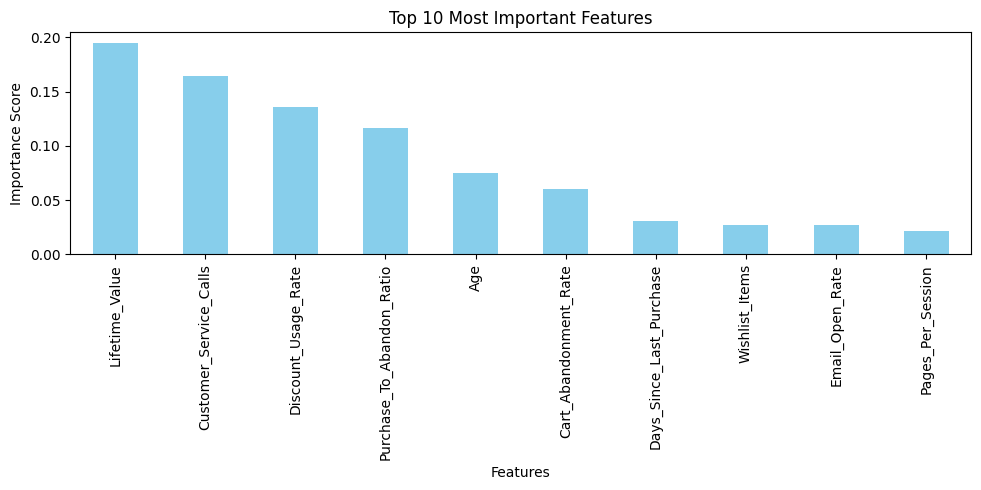

In [ ]:
#اذا حختار XGBoost

#  (Feature Importance)

import matplotlib.pyplot as plt
import pandas as pd

importances = xgb_tuned.feature_importances_

feature_imp = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))

feature_imp.head(10).plot(kind='bar', color='skyblue')

plt.title('Top 10 Most Important Features')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.tight_layout()
plt.show()

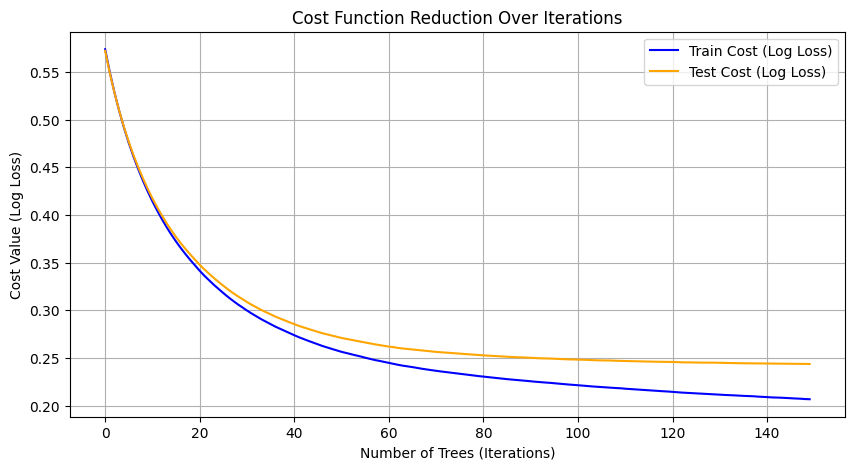

In [ ]:

# حساب ورسم دالة التكلفة (Cost Function) عبر منحنى التعلم

import matplotlib.pyplot as plt
from xgboost import XGBClassifier

xgb_cost_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

#  تدريب الموديل ومراقبة التكلفة على بيانات التدريب والاختبار معاً
xgb_cost_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

eval_results = xgb_cost_model.evals_result()
train_loss_values = eval_results['validation_0']['logloss']
test_loss_values = eval_results['validation_1']['logloss']

plt.figure(figsize=(10, 5))
plt.plot(train_loss_values, label='Train Cost (Log Loss)', color='blue')
plt.plot(test_loss_values, label='Test Cost (Log Loss)', color='orange')

plt.title('Cost Function Reduction Over Iterations')
plt.xlabel('Number of Trees (Iterations)')
plt.ylabel('Cost Value (Log Loss)')
plt.legend()
plt.grid(True)
plt.show()

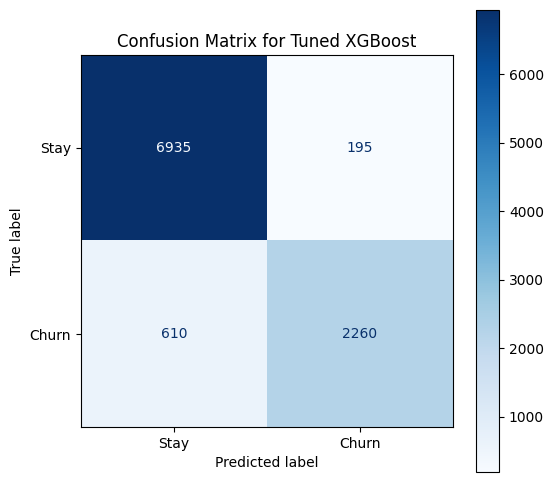

In [ ]:

#حساب ورسم  (Confusion Matrix) لنموذج XGBoost

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# حساب قيم مصفوفة الإرباك بناء على التوقعات والقيم الحقيقية
cm = confusion_matrix(y_test, y_pred_xgb_tuned)

# إنشاء لوحة الرسم
plt.figure(figsize=(6, 6))

# إعداد أداة العرض مع تحديد المسميات
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stay', 'Churn'])

#رسم مصفوفة الإرباك بالتدرج اللوني الأزرق
disp.plot(cmap=plt.cm.Blues, ax=plt.gca(), values_format='d')

# وضع العنوان الرئيسي للرسمة
plt.title('Confusion Matrix for Tuned XGBoost')
plt.grid(False)
plt.show()

In [ ]:

# حفظ الموديل النهائي والـ Scaler لاستخدامهما مستقبلاً

import joblib

# 1. حفظ ملف نموذج XGBoost المطور كاملاً
joblib.dump(xgb_tuned, 'final_xgb_churn_model.pkl')

# 2. حفظ ملف التحجيم (إذا قمتِ بتحجيم البيانات سابقاً باسم scaler)
# في حال لم تستخدمي scaler، يمكنكِ تجاهل هذا السطر أو وضع علامة # قبله
try:
    joblib.dump(scaler, 'scaler.pkl')
    print("تم حفظ ملف التحجيم بنجاح باسم 'scaler.pkl'")
except NameError:
    print("ملاحظة: لم يتم العثور على متغير باسم scaler، تم حفظ الموديل فقط.")

print("\n============================================================")
print("'final_xgb_churn_model.pkl'")
print("الملفات الآن جاهزة تماماً للتسليم والتطبيق الفوري!")
print("============================================================")

تم حفظ ملف التحجيم بنجاح باسم 'scaler.pkl'

'final_xgb_churn_model.pkl'
الملفات الآن جاهزة تماماً للتسليم والتطبيق الفوري!
